<a href="https://colab.research.google.com/github/mcundins/cse6242-project/blob/main/kmeans_food_desert_risk_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-means clustering (unsupervised learning)

Training model on 2019 dataset

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pickle

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


| Variable | Description |
|----------|-------------|
|tract_id | census tract number |
|Urban | flag for urban tract |
|Pop2010 | population count from 2010 census |
|OHU2010 | occupied housing unit count from 2010 census |
|GroupQuartersFlag | flag for tract where >=67%; group quarters, tract with high share |
|NUMGQTRS | count of tract population residing in group quarters |
|PCTGQTRS | percent of tract population residing in group quarters |
|LowIncomeTracts | flag for low income tract |
|PovertyRate | share of the tract population living with income at or below the Federal poverty thresholds for family size |
|MedianFamilyIncome | tract median family income |
|TractLOWI | total count of low-income population in tract |
|TractKids | total count of children age 0-17 in tract |
|TractSeniors | total count of seniors age 65+ in tract |
|TractWhite | total count of white population in tract |
|TractBlack | total count of black or african american population in tract |
|TractAsian | total count of asian population in tract |
|TractNHOPI | total count of native hawaiian and other pacific islander population in tract |
|TractAIAN | total count of american indian and alaska native population in tract |
|TractOMultir | total count of other/multiple race population in tract |
|TractHispanic | total count of hispanic or latino population in tract |
|TractHUNV | total count of housing units without a vehicle in tract |
|TractSNAP | total count of housing units receiving SNAP benefits in tract |

need additional variables to account for distance from food sources, add the following variables:
- LATracts_half: flag for low access tract when considering 1/2 mile distance
- LATracts1: flag for low access tract when considering 1 mile distance
- LATractsVehicle_20: flag for tract where >=100 of households do not have a vehicle, and beyond 1/2 mile from supermarket or >=500 individuals are beyond 20 miles from supermarket or >=33% of individuals are beyond 20 miles from supermarket; low access tract using vehicle access and at 20 miles in rural areas

## Using 2019 Data

In [ ]:
df_2019 = pd.read_csv('/content/drive/MyDrive/Food_Desert_Data/cleaned_2019.csv')
df_2019 = df_2019[[i for i in df_2019.columns if 'original' not in i]]
df_2019 = df_2019[[i for i in df_2019.columns if 'qa' not in i]]
df_2019 = df_2019[[i for i in df_2019.columns if 'income' not in i]]
df_2019 = df_2019.iloc[:, :-4]
df_2019 = df_2019.drop(columns=['fd_label', 'label_status', 'label_reason', 'FD_2'])

#leading 0
df_2019['tract_id'] = df_2019['tract_id'].astype(str).str.zfill(11)

#renaming 'State' as state_name
df_2019 = df_2019.rename(columns={'State': 'state_name'})

#creating state column with 2 beg digits of tract_id
df_2019['state'] = df_2019['tract_id'].str[:2]

df_2019.head()


,tract_id,state_name,County,meta_dataset_version,meta_population_census_year,meta_tract_vintage,clean__Urban,clean__population_total,clean__occupied_housing_units_total,clean__GroupQuartersFlag,...,clean__PovertyRate,clean__MedianFamilyIncome,clean__TractLOWI,clean__TractHUNV,clean__TractSNAP,clean__LATracts_half,clean__LATracts1,clean__LATractsVehicle_20,clean__low_access_population_1_20,state
0,01001020100,Alabama,Autauga County,2019,2010,2010,1.0,1912.0,693.0,0.0,...,11.3,81250.0,455.0,6.0,102.0,1.0,1.0,0.0,1896.0,01
1,01001020200,Alabama,Autauga County,2019,2010,2010,1.0,2170.0,743.0,0.0,...,17.9,49000.0,802.0,89.0,156.0,1.0,1.0,0.0,1261.0,01
2,01001020300,Alabama,Autauga County,2019,2010,2010,1.0,3373.0,1256.0,0.0,...,15.0,62609.0,1306.0,99.0,172.0,1.0,1.0,0.0,1552.0,01
3,01001020400,Alabama,Autauga County,2019,2010,2010,1.0,4386.0,1722.0,0.0,...,2.8,70607.0,922.0,21.0,98.0,1.0,1.0,0.0,1363.0,01
4,01001020500,Alabama,Autauga County,2019,2010,2010,1.0,10766.0,4082.0,0.0,...,15.2,96334.0,2242.0,230.0,339.0,1.0,1.0,1.0,2643.0,01


## Data Processing/EDA

In [ ]:
df_2019.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72531 entries, 0 to 72530
Data columns (total 32 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   tract_id                             72531 non-null  object 
 1   state_name                           72531 non-null  object 
 2   County                               72531 non-null  object 
 3   meta_dataset_version                 72531 non-null  int64  
 4   meta_population_census_year          72531 non-null  int64  
 5   meta_tract_vintage                   72531 non-null  int64  
 6   clean__Urban                         72531 non-null  float64
 7   clean__population_total              72531 non-null  float64
 8   clean__occupied_housing_units_total  72531 non-null  float64
 9   clean__GroupQuartersFlag             72531 non-null  float64
 10  clean__NUMGQTRS                      72506 non-null  float64
 11  clean__PCTGQTRS             

In [ ]:
df_2019.isna().sum()

,0
tract_id,0
state_name,0
County,0
meta_dataset_version,0
meta_population_census_year,0
meta_tract_vintage,0
clean__Urban,0
clean__population_total,0
clean__occupied_housing_units_total,0
clean__GroupQuartersFlag,0


In [ ]:
df_2019["clean__NUMGQTRS"] = df_2019["clean__NUMGQTRS"].fillna(df_2019["clean__NUMGQTRS"].median())
df_2019["clean__PCTGQTRS"] = df_2019["clean__PCTGQTRS"].fillna(df_2019["clean__PCTGQTRS"].median())

df_2019["clean__TractKids"] = df_2019["clean__TractKids"].fillna(df_2019["clean__TractKids"].median())
df_2019["clean__TractSeniors"] = df_2019["clean__TractSeniors"].fillna(df_2019["clean__TractSeniors"].median())
df_2019["clean__TractWhite"] = df_2019["clean__TractWhite"].fillna(df_2019["clean__TractWhite"].median())
df_2019["clean__TractBlack"] = df_2019["clean__TractBlack"].fillna(df_2019["clean__TractBlack"].median())
df_2019["clean__TractAsian"] = df_2019["clean__TractAsian"].fillna(df_2019["clean__TractAsian"].median())
df_2019["clean__TractNHOPI"] = df_2019["clean__TractNHOPI"].fillna(df_2019["clean__TractNHOPI"].median())
df_2019["clean__TractAIAN"] = df_2019["clean__TractAIAN"].fillna(df_2019["clean__TractAIAN"].median())
df_2019["clean__TractOMultir"] = df_2019["clean__TractOMultir"].fillna(df_2019["clean__TractOMultir"].median())
df_2019["clean__TractHispanic"] = df_2019["clean__TractHispanic"].fillna(df_2019["clean__TractHispanic"].median())

df_2019["clean__PovertyRate"] = df_2019["clean__PovertyRate"].fillna(df_2019["clean__PovertyRate"].median())
df_2019["clean__MedianFamilyIncome"] = df_2019["clean__MedianFamilyIncome"].fillna(df_2019["clean__MedianFamilyIncome"].median())

df_2019["clean__TractLOWI"] = df_2019["clean__TractLOWI"].fillna(df_2019["clean__TractLOWI"].median())
df_2019["clean__TractHUNV"] = df_2019["clean__TractHUNV"].fillna(df_2019["clean__TractHUNV"].median())
df_2019["clean__TractSNAP"] = df_2019["clean__TractSNAP"].fillna(df_2019["clean__TractSNAP"].median())

df_2019["clean__low_access_population_1_20"] = df_2019["clean__low_access_population_1_20"].fillna(0)

In [ ]:
df_2019.columns.tolist()

['tract_id',
 'state_name',
 'County',
 'meta_dataset_version',
 'meta_population_census_year',
 'meta_tract_vintage',
 'clean__Urban',
 'clean__population_total',
 'clean__occupied_housing_units_total',
 'clean__GroupQuartersFlag',
 'clean__NUMGQTRS',
 'clean__PCTGQTRS',
 'clean__TractKids',
 'clean__TractSeniors',
 'clean__TractWhite',
 'clean__TractBlack',
 'clean__TractAsian',
 'clean__TractNHOPI',
 'clean__TractAIAN',
 'clean__TractOMultir',
 'clean__TractHispanic',
 'clean__LowIncomeTracts',
 'clean__PovertyRate',
 'clean__MedianFamilyIncome',
 'clean__TractLOWI',
 'clean__TractHUNV',
 'clean__TractSNAP',
 'clean__LATracts_half',
 'clean__LATracts1',
 'clean__LATractsVehicle_20',
 'clean__low_access_population_1_20',
 'state']

In [ ]:
df_2019 = df_2019[['tract_id','state','state_name', 'County',
                    'clean__Urban','clean__population_total',
                    'clean__occupied_housing_units_total',
                    'clean__GroupQuartersFlag','clean__NUMGQTRS',
                    'clean__PCTGQTRS', 'clean__TractKids',
                    'clean__TractSeniors','clean__TractWhite',
                    'clean__TractBlack','clean__TractAsian',
                    'clean__TractNHOPI','clean__TractAIAN',
                    'clean__TractOMultir','clean__TractHispanic',
                    'clean__LowIncomeTracts','clean__PovertyRate',
                    'clean__MedianFamilyIncome','clean__TractLOWI',
                    'clean__TractHUNV', 'clean__TractSNAP',
                    'clean__LATracts_half','clean__LATracts1',
                    'clean__LATractsVehicle_20']]

In [ ]:
df_2019.isna().sum()

,0
tract_id,0
state,0
state_name,0
County,0
clean__Urban,0
clean__population_total,0
clean__occupied_housing_units_total,0
clean__GroupQuartersFlag,0
clean__NUMGQTRS,0
clean__PCTGQTRS,0


## Correlation Matrix

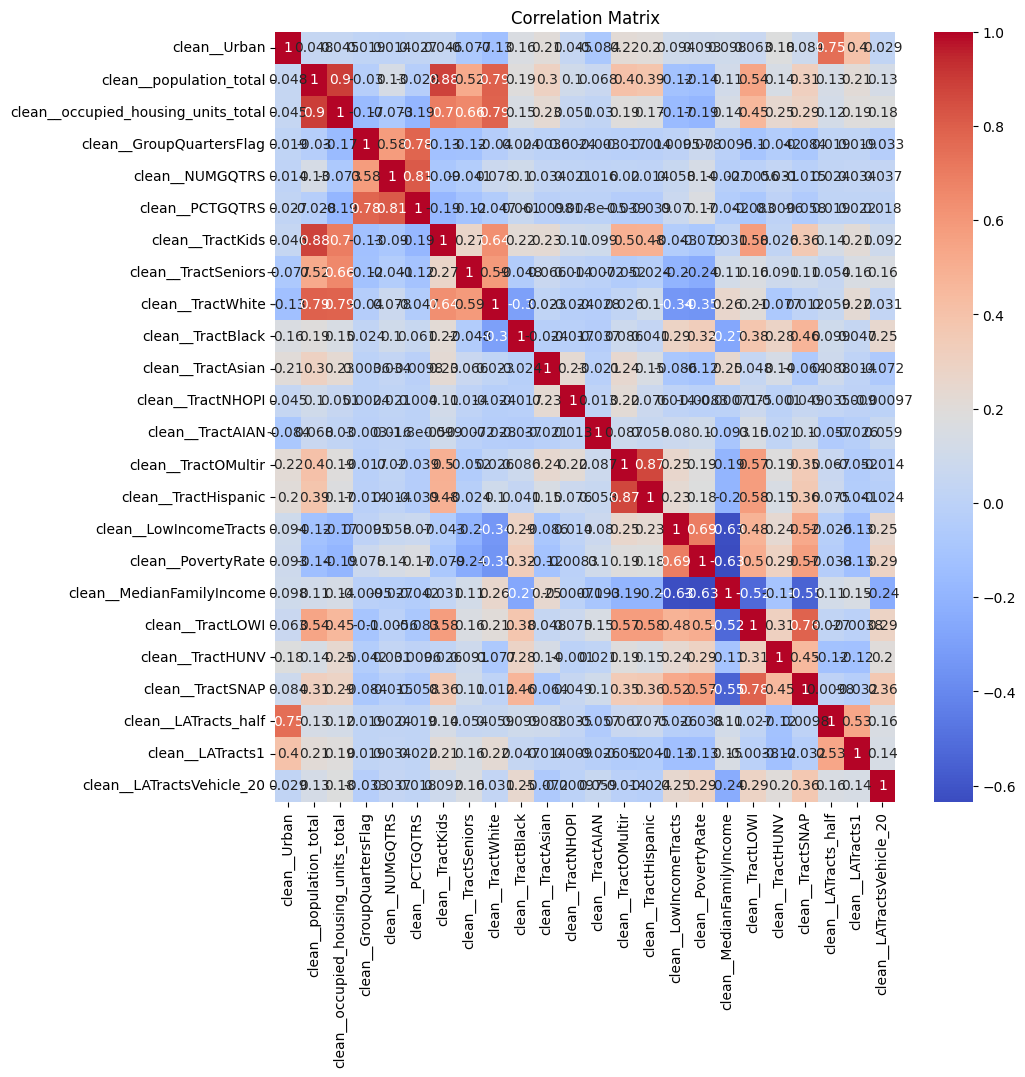

In [ ]:
X = df_2019.drop(columns=['tract_id', 'state','state_name','County' ])

corr_matrix = X.corr()

plt.figure(figsize=(10, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [ ]:
corr_threshold = 0.80

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column].abs() > corr_threshold)
]

print(high_corr_features)

['clean__occupied_housing_units_total', 'clean__PCTGQTRS', 'clean__TractKids', 'clean__TractHispanic']


## K-Means Model with ALL Columns

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

X_train = X

pipeline.fit(X_train) #fitting in standardized pipeline

df_2019['cluster_group'] = pipeline.predict(X_train)

print(df_2019['cluster_group'].value_counts().sort_index())


cluster_group
0    21621
1    18359
2    32551
Name: count, dtype: int64


/tmp/ipykernel_12981/2145571916.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_2019['cluster_group'] = pipeline.predict(X_train)


In [ ]:
df_2019.groupby('cluster_group')[X.columns].mean().round(2)

,clean__Urban,clean__population_total,clean__occupied_housing_units_total,clean__GroupQuartersFlag,clean__NUMGQTRS,clean__PCTGQTRS,clean__TractKids,clean__TractSeniors,clean__TractWhite,clean__TractBlack,...,clean__TractHispanic,clean__LowIncomeTracts,clean__PovertyRate,clean__MedianFamilyIncome,clean__TractLOWI,clean__TractHUNV,clean__TractSNAP,clean__LATracts_half,clean__LATracts1,clean__LATractsVehicle_20
cluster_group,,,,,,,,,,,,,,,,,,,,,
0,0.83,5864.29,2242.79,0.00,87.00,1.43,1409.85,812.01,4788.70,350.31,...,595.02,0.06,7.89,99333.34,1270.62,115.63,151.33,0.81,0.59,0.20
1,0.90,4754.26,1693.87,0.00,136.26,2.70,1259.93,498.65,2481.38,1197.17,...,1516.04,0.96,27.38,46221.68,2489.50,278.57,414.00,0.71,0.30,0.46
2,0.63,2908.36,1140.58,0.01,110.66,3.56,631.72,416.50,2287.86,288.07,...,300.46,0.35,13.15,79420.35,838.12,86.29,115.53,0.49,0.19,0.08


cluster group
*   0: low-risk
*   1: high-risk
*   2: medium-risk



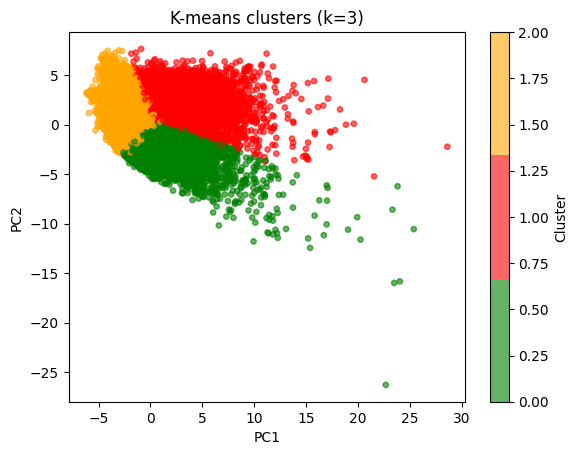

Explained variance ratio: [0.21074851 0.16935182]
Total explained variance: 0.38010033238581953


In [ ]:
#PCA with all columns

from matplotlib.colors import ListedColormap

pca_allcols = PCA(n_components=2)
pcs_allcols = pca_allcols.fit_transform(X_scaled)


cmap_x = ListedColormap(['green', 'red', 'orange'])
plt.scatter(pcs_allcols[:, 0],
            pcs_allcols[:, 1],
            c=df_2019['cluster_group'],
            cmap=cmap_x, alpha=0.6, s=15)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-means clusters (k=3)')
plt.colorbar(label='Cluster')

plt.show()

print("Explained variance ratio:", pca_allcols.explained_variance_ratio_)

print("Total explained variance:", sum(pca_allcols.explained_variance_ratio_))

In [ ]:
df_2019.head()

,tract_id,state,state_name,County,clean__Urban,clean__population_total,clean__occupied_housing_units_total,clean__GroupQuartersFlag,clean__NUMGQTRS,clean__PCTGQTRS,...,clean__LowIncomeTracts,clean__PovertyRate,clean__MedianFamilyIncome,clean__TractLOWI,clean__TractHUNV,clean__TractSNAP,clean__LATracts_half,clean__LATracts1,clean__LATractsVehicle_20,cluster_group
0,01001020100,01,Alabama,Autauga County,1.0,1912.0,693.0,0.0,0.0,0.00,...,0.0,11.3,81250.0,455.0,6.0,102.0,1.0,1.0,0.0,2
1,01001020200,01,Alabama,Autauga County,1.0,2170.0,743.0,0.0,181.0,8.34,...,1.0,17.9,49000.0,802.0,89.0,156.0,1.0,1.0,0.0,2
2,01001020300,01,Alabama,Autauga County,1.0,3373.0,1256.0,0.0,0.0,0.00,...,0.0,15.0,62609.0,1306.0,99.0,172.0,1.0,1.0,0.0,2
3,01001020400,01,Alabama,Autauga County,1.0,4386.0,1722.0,0.0,0.0,0.00,...,0.0,2.8,70607.0,922.0,21.0,98.0,1.0,1.0,0.0,0
4,01001020500,01,Alabama,Autauga County,1.0,10766.0,4082.0,0.0,181.0,1.68,...,0.0,15.2,96334.0,2242.0,230.0,339.0,1.0,1.0,1.0,0


In [ ]:

model_cols = ['clean__Urban','clean__population_total',
                    'clean__occupied_housing_units_total',
                    'clean__GroupQuartersFlag','clean__NUMGQTRS',
                    'clean__PCTGQTRS', 'clean__TractKids',
                    'clean__TractSeniors','clean__TractWhite',
                    'clean__TractBlack','clean__TractAsian',
                    'clean__TractNHOPI','clean__TractAIAN',
                    'clean__TractOMultir','clean__TractHispanic',
                    'clean__LowIncomeTracts','clean__PovertyRate',
                    'clean__MedianFamilyIncome','clean__TractLOWI',
                    'clean__TractHUNV', 'clean__TractSNAP',
                    'clean__LATracts_half','clean__LATracts1',
                    'clean__LATractsVehicle_20']

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=3, random_state=42, n_init=10)),
])

pipe.fit(X[model_cols])


Pipeline(steps=[('scaler', StandardScaler()),
                ('kmeans', KMeans(n_clusters=3, n_init=10, random_state=42))])

In [ ]:
bundle = {
    "pipeline": pipe,
    "model_cols": model_cols,
    "id_col": "tract_id",
    "risk_map": {0: 0, 1: 1, 2: 2},
    "risk_names": {0: "low", 1: "high", 2: "mid"},
}

with open("cluster_model.pkl", "wb") as f:
    pickle.dump(bundle, f)